# Kazakhstan Tenge Coin Classification
**Computer Vision — Assignment 1** · Kurbankhozha Sabira, SE-2424

Goal: classify photos of Kazakhstan coins into 5 denominations — **5, 10, 20, 50 and 100 tenge** — using a self-collected dataset.

Pipeline:
1. Dataset overview
2. Preprocessing & augmentation
3. Baseline 1 — HOG + colour histogram + SVM
4. Baseline 2 — simple CNN trained from scratch
5. Improved model — transfer learning (ResNet18 pretrained on ImageNet, fine-tuned)
6. Evaluation & analysis — accuracy, precision, recall, F1, confusion matrices, errors, Grad-CAM

All figures and tables are also saved to `results/` for the report.

## 0. Setup
Install once (in the project's virtual environment):
```
pip install torch torchvision scikit-learn scikit-image matplotlib pandas jupyter
```
The notebook expects the `dataset/` folder (output of `extract_frames.py`) next to it.

In [1]:
import os, time, copy, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_recall_fscore_support)

DATA_DIR = Path("../dataset")
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

CLASSES = ["5_tenge", "10_tenge", "20_tenge", "50_tenge", "100_tenge"]
SHORT = ["5", "10", "20", "50", "100"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

SETUPS = {1: "Paper + daylight", 2: "Dark fabric + lamp", 3: "Cutting board + daylight",
          4: "Palm + lamp", 5: "Paper + warm side lamp", 6: "Cutting board + flash"}

SEED = 42
random.seed(SEED); np.random.seed(SEED)
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams["figure.dpi"] = 110

Matplotlib is building the font cache; this may take a moment.


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

torch.manual_seed(SEED)
DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.14.1 | device: mps


## 1. Dataset overview
Images were extracted from short smartphone videos (one coin of each denomination, both sides, 6 background/lighting setups) and automatically cropped around the coin with a random margin, so the coin size in the image varies.
**The split is done by video, not by image**: neighbouring frames of one video are almost identical, so a random split would leak test images into training.

| Setup | Background + light | Split |
|---|---|---|
| 1 | Paper + daylight | test |
| 2 | Dark fabric + lamp | train |
| 3 | Cutting board + daylight | val |
| 4 | Palm + lamp | train |
| 5 | Paper + warm side lamp | train |
| 6 | Cutting board + flash | train |

In [3]:
rows = []
for split in ["train", "val", "test"]:
    for c in CLASSES:
        for p in sorted((DATA_DIR / split / c).glob("*.jpg")):
            rows.append({"path": p.relative_to(DATA_DIR).as_posix(), "split": split,
                         "class": c, "label": CLASS_TO_IDX[c]})
df = pd.DataFrame(rows)

meta_file = DATA_DIR / "metadata.csv"
if meta_file.exists():
    meta = pd.read_csv(meta_file)
    keep = [c for c in ["path", "video", "side", "setup", "crop_method", "margin"] if c in meta.columns]
    df = df.merge(meta[keep], on="path", how="left")   # files deleted by hand simply disappear

counts = df.pivot_table(index="class", columns="split", values="path", aggfunc="count")
counts = counts.reindex(index=CLASSES, columns=["train", "val", "test"]).fillna(0).astype(int)
counts["total"] = counts.sum(axis=1)
counts.loc["TOTAL"] = counts.sum()
counts.to_csv(RESULTS / "dataset_counts.csv")
counts

split,train,val,test,total
class,,,,
5_tenge,145,39,36,220
10_tenge,143,40,40,223
20_tenge,140,38,39,217
50_tenge,138,37,39,214
100_tenge,156,40,39,235
TOTAL,722,194,193,1109


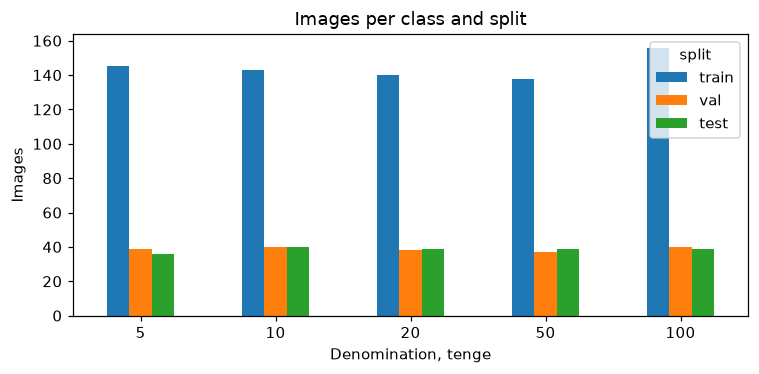

side,obverse,reverse
class,,
5_tenge,114,106
10_tenge,111,112
20_tenge,107,110
50_tenge,109,105
100_tenge,116,119


crop_method
circle      928
ellipse     130
neighbor     51
Name: images by crop method, dtype: int64

In [4]:
ax = counts.drop("TOTAL")[["train", "val", "test"]].plot.bar(figsize=(7, 3.5), rot=0)
ax.set_xticklabels(SHORT); ax.set_xlabel("Denomination, tenge"); ax.set_ylabel("Images")
ax.set_title("Images per class and split")
plt.tight_layout(); plt.savefig(RESULTS / "class_distribution.png"); plt.show()

if "side" in df.columns:
    display(df.pivot_table(index="class", columns="side", values="path", aggfunc="count").reindex(CLASSES))
if "crop_method" in df.columns:
    display(df["crop_method"].value_counts().rename("images by crop method"))

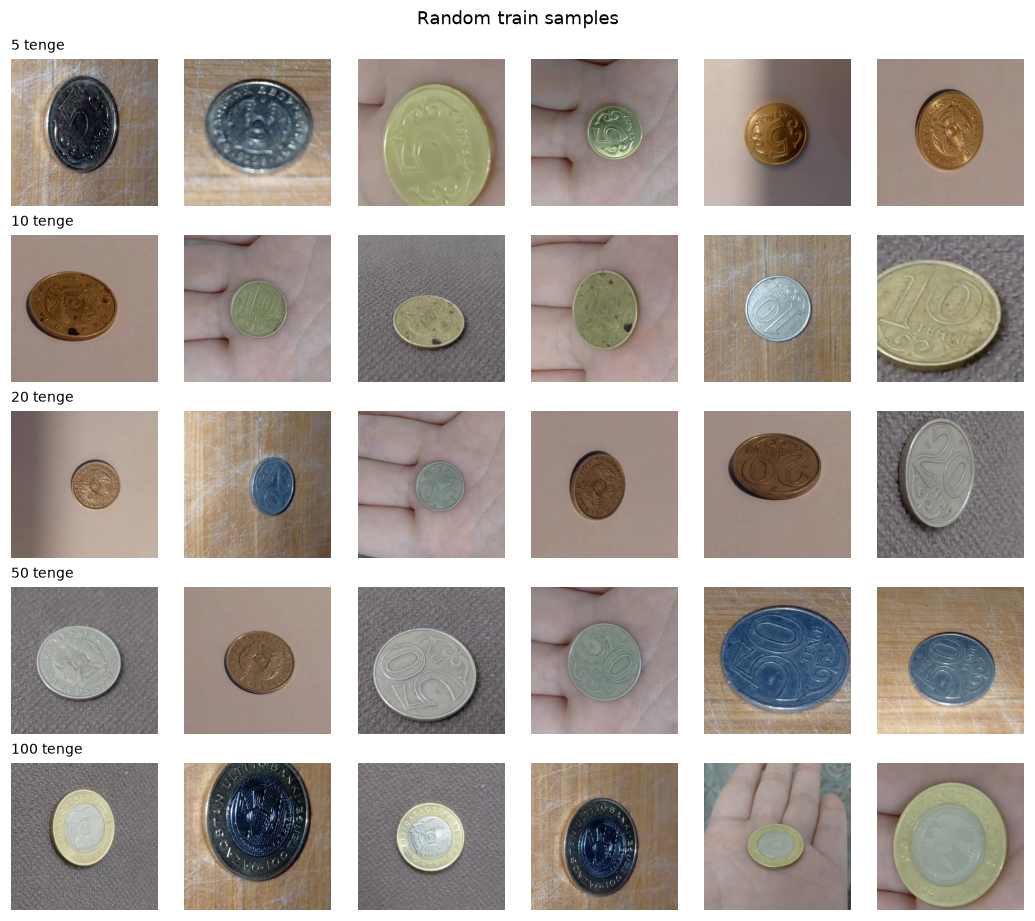

In [5]:
def show_samples(split="train", n=6, seed=SEED):
    fig, axes = plt.subplots(len(CLASSES), n, figsize=(n * 1.6, len(CLASSES) * 1.7))
    for r, c in enumerate(CLASSES):
        sub = df[(df.split == split) & (df["class"] == c)]
        pick = sub.sample(min(n, len(sub)), random_state=seed)
        for k, ax in enumerate(axes[r]):
            ax.axis("off")
            if k < len(pick):
                ax.imshow(Image.open(DATA_DIR / pick.iloc[k].path))
        axes[r][0].set_title(f"{SHORT[r]} tenge", loc="left", fontsize=9)
    plt.suptitle(f"Random {split} samples"); plt.tight_layout()
    plt.savefig(RESULTS / f"samples_{split}.png"); plt.show()

show_samples("train")

## 2. Preprocessing & augmentation
**Preprocessing** (all splits): resize to 224×224, convert to tensor, normalize with ImageNet mean/std (needed for the pretrained model; harmless for the others).

**Augmentation** (training only), chosen for coins specifically:
- **Random rotation 0–360°** — a coin can lie at any angle.
- **Random resized crop (60–100%)** — extra variation of coin size / distance.
- **Random perspective** (30% of images) — imitates a tilted camera.
- **Brightness / contrast jitter** — different lighting.
- **Only weak saturation/hue jitter** — denominations differ by metal colour, strong colour changes could turn one coin into another.
- **No horizontal flip** — a mirrored coin (mirrored digits and text) never appears in reality.
- **Gaussian blur** (20%) — out-of-focus frames.

In [6]:
IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomRotation(180),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomApply([transforms.RandomPerspective(distortion_scale=0.25, p=1.0)], p=0.3),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.15, hue=0.02),
    transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class CoinDataset(Dataset):
    def __init__(self, frame, tf):
        self.paths = [DATA_DIR / p for p in frame["path"]]
        self.labels = frame["label"].tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), self.labels[i]

def denorm(t):
    x = t.permute(1, 2, 0).cpu().numpy() * np.array(STD) + np.array(MEAN)
    return np.clip(x, 0, 1)

train_df, val_df, test_df = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
BATCH = 32
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(CoinDataset(train_df, train_tf), batch_size=BATCH, shuffle=True, generator=g)
val_loader   = DataLoader(CoinDataset(val_df, eval_tf), batch_size=BATCH)
test_loader  = DataLoader(CoinDataset(test_df, eval_tf), batch_size=BATCH)
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}")

train 722 | val 194 | test 193


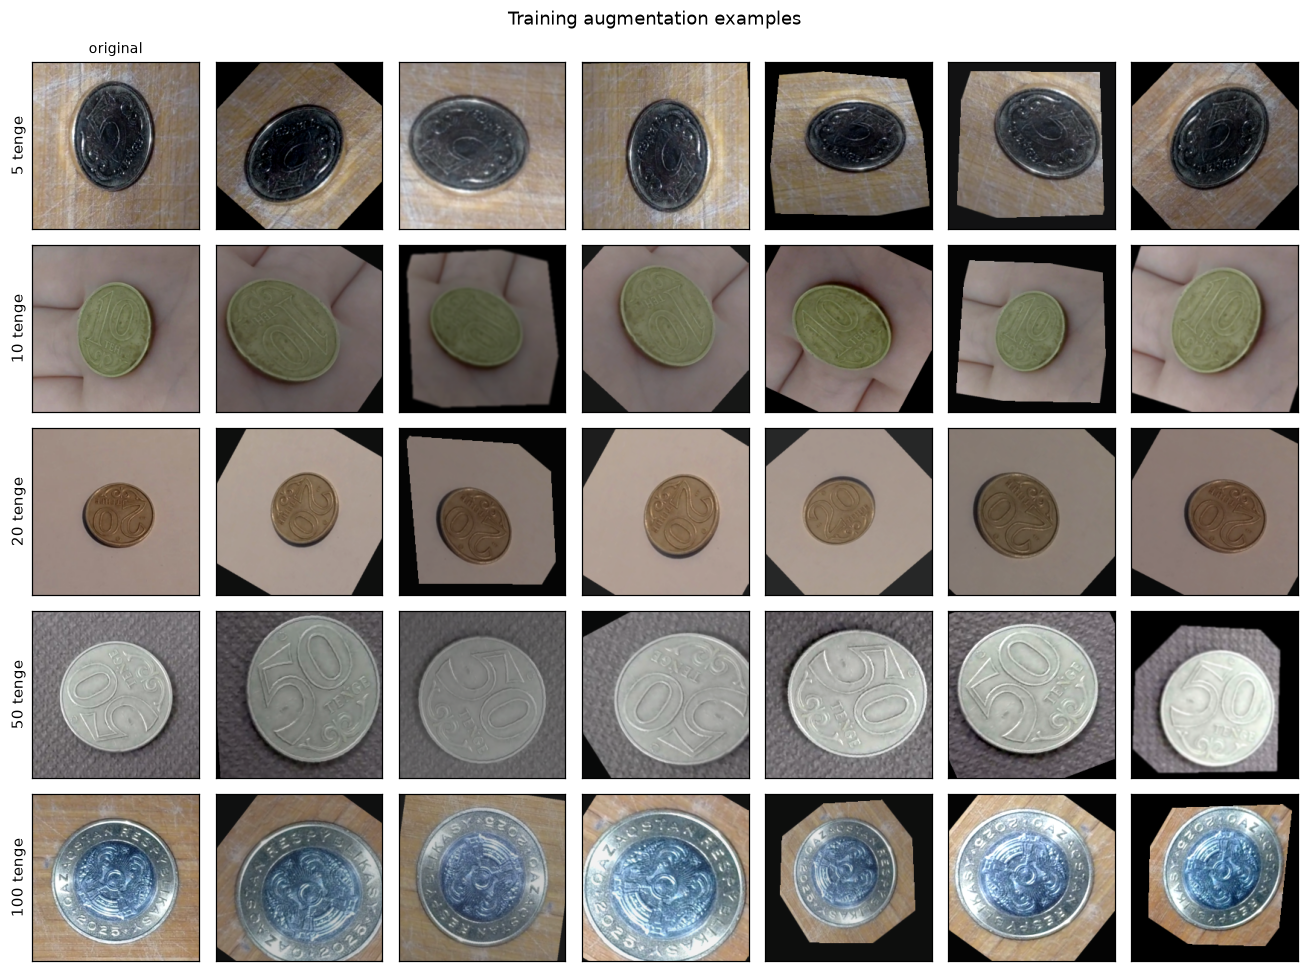

In [7]:
# Augmentation examples: original + 6 augmented versions of the same image
examples = train_df.groupby("label").sample(1, random_state=SEED).sort_values("label")
fig, axes = plt.subplots(len(examples), 7, figsize=(12, len(examples) * 1.8))
for r, (_, row) in enumerate(examples.iterrows()):
    img = Image.open(DATA_DIR / row.path).convert("RGB")
    axes[r][0].imshow(img.resize((IMG_SIZE, IMG_SIZE))); axes[r][0].set_title("original" if r == 0 else "", fontsize=9)
    for k in range(1, 7):
        axes[r][k].imshow(denorm(train_tf(img)))
    axes[r][0].set_ylabel(f"{SHORT[row.label]} tenge")
    for ax in axes[r]: ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Training augmentation examples"); plt.tight_layout()
plt.savefig(RESULTS / "augmentation_examples.png"); plt.show()

## 3. Baseline 1 — HOG + colour histogram + SVM
Classic hand-crafted features:
- **HOG** (histogram of oriented gradients) on a 128×128 grayscale image — shape and relief of the digits;
- **HSV colour histogram** — colour of the metal.

Features are standardized and fed to an RBF-kernel SVM. `C` is chosen on the validation set. The SVM sees the images without augmentation, as is usual for classic methods.

In [8]:
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEAT_SIZE = 128

def extract_features(path):
    img = Image.open(DATA_DIR / path).convert("RGB").resize((FEAT_SIZE, FEAT_SIZE))
    gray = np.asarray(img.convert("L"), dtype=np.float32) / 255.0
    h = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), feature_vector=True)
    hsv = np.asarray(img.convert("HSV"))
    hist = np.concatenate([np.histogram(hsv[..., ch], bins=b, range=(0, 256), density=True)[0]
                           for ch, b in zip(range(3), (16, 8, 8))])
    return np.concatenate([h, hist])

def features_for(frame):
    return np.stack([extract_features(p) for p in frame["path"]]), frame["label"].to_numpy()

t0 = time.time()
X_tr, y_tr = features_for(df[df.split == "train"])
X_va, y_va = features_for(df[df.split == "val"])
X_te, y_te = features_for(df[df.split == "test"])
print("feature vector length:", X_tr.shape[1], f"| extraction {time.time() - t0:.1f}s")

best_C, best_acc = None, -1
for C in [0.1, 1, 10, 100]:
    clf = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C, gamma="scale"))
    clf.fit(X_tr, y_tr)
    acc = accuracy_score(y_va, clf.predict(X_va))
    print(f"C={C:<5} val acc={acc:.3f}")
    if acc > best_acc:
        best_C, best_acc = C, acc

t0 = time.time()
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=best_C, gamma="scale"))
svm.fit(X_tr, y_tr)
svm_time = time.time() - t0
svm_pred = svm.predict(X_te)
print(f"\nbest C={best_C} | test accuracy {accuracy_score(y_te, svm_pred):.3f}")

feature vector length: 1796 | extraction 4.4s
C=0.1   val acc=0.206
C=1     val acc=0.376
C=10    val acc=0.387
C=100   val acc=0.387

best C=10 | test accuracy 0.218


## Shared training utilities
Used for both neural networks: cross-entropy loss (with light label smoothing), the best epoch is selected by **validation loss**, early stopping if validation loss does not improve for `patience` epochs.

In [9]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

def fit(model, optimizer, epochs, scheduler=None, patience=5, history=None):
    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
    history = history or {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss = min(history["val_loss"], default=float("inf"))
    best_state = copy.deepcopy(model.state_dict())
    bad = 0
    for ep in range(epochs):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        if scheduler is not None:
            scheduler.step()
        for k, v in zip(history, (tl, vl, ta, va)):
            history[k].append(v)
        print(f"epoch {len(history['val_loss']):>2} | train loss {tl:.3f} acc {ta:.3f} | "
              f"val loss {vl:.3f} acc {va:.3f} | {time.time() - t0:.0f}s")
        if vl < best_loss:
            best_loss, best_state, bad = vl, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                print("early stopping"); break
    model.load_state_dict(best_state)
    return history

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, probs = [], []
    for x, _ in loader:
        out = model(x.to(DEVICE))
        probs.append(F.softmax(out, 1).cpu()); preds.append(out.argmax(1).cpu())
    return torch.cat(preds).numpy(), torch.cat(probs).numpy()

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def plot_history(h, title, fname):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.3))
    a1.plot(h["train_loss"], label="train"); a1.plot(h["val_loss"], label="val"); a1.set_title("Loss")
    a2.plot(h["train_acc"], label="train"); a2.plot(h["val_acc"], label="val"); a2.set_title("Accuracy")
    for a in (a1, a2): a.set_xlabel("epoch"); a.legend(); a.grid(alpha=0.3)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(RESULTS / fname); plt.show()

## 4. Baseline 2 — simple CNN from scratch
Four convolution blocks (Conv → BatchNorm → ReLU → MaxPool), global average pooling, dropout and a linear classifier. Trained with the same augmentation as the improved model.

parameters: 390,661
epoch  1 | train loss 1.688 acc 0.199 | val loss 1.587 acc 0.216 | 18s
epoch  2 | train loss 1.508 acc 0.299 | val loss 1.685 acc 0.206 | 10s
epoch  3 | train loss 1.438 acc 0.385 | val loss 1.934 acc 0.196 | 9s
epoch  4 | train loss 1.397 acc 0.377 | val loss 1.796 acc 0.247 | 9s
epoch  5 | train loss 1.364 acc 0.421 | val loss 1.541 acc 0.247 | 9s
epoch  6 | train loss 1.405 acc 0.375 | val loss 1.657 acc 0.284 | 9s
epoch  7 | train loss 1.383 acc 0.363 | val loss 1.753 acc 0.299 | 12s
epoch  8 | train loss 1.343 acc 0.385 | val loss 1.667 acc 0.216 | 9s
epoch  9 | train loss 1.315 acc 0.432 | val loss 1.761 acc 0.216 | 11s
epoch 10 | train loss 1.291 acc 0.431 | val loss 1.831 acc 0.253 | 19s
epoch 11 | train loss 1.250 acc 0.479 | val loss 1.705 acc 0.320 | 16s
epoch 12 | train loss 1.203 acc 0.524 | val loss 1.896 acc 0.294 | 11s
epoch 13 | train loss 1.232 acc 0.500 | val loss 1.524 acc 0.304 | 10s
epoch 14 | train loss 1.199 acc 0.499 | val loss 1.949 acc 0.2

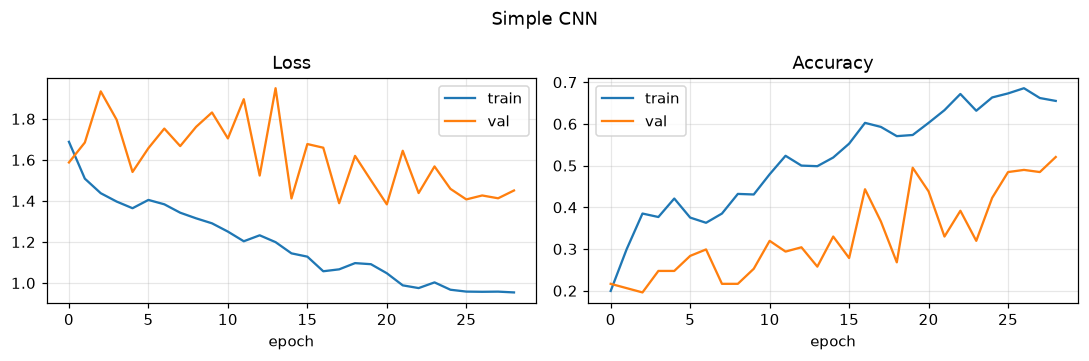

test accuracy 0.342 | training time 4.9 min


In [10]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes=len(CLASSES)):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

torch.manual_seed(SEED)
cnn = SimpleCNN().to(DEVICE)
print(f"parameters: {count_params(cnn):,}")

CNN_EPOCHS = 30
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CNN_EPOCHS)
t0 = time.time()
cnn_hist = fit(cnn, opt, CNN_EPOCHS, sched, patience=8)
cnn_time = time.time() - t0
plot_history(cnn_hist, "Simple CNN", "curves_simple_cnn.png")
cnn_pred, cnn_prob = predict(cnn, test_loader)
print(f"test accuracy {accuracy_score(test_df.label, cnn_pred):.3f} | training time {cnn_time / 60:.1f} min")

## 5. Improved model — transfer learning
A network pretrained on ImageNet already knows edges, textures and shapes; we only adapt it to coins. Two stages:
1. **Feature extraction** — freeze the backbone, train only the new 5-class head (lr 1e-3).
2. **Fine-tuning** — unfreeze the whole network, train with a small learning rate (1e-4, cosine schedule).

`ARCHS` can list several backbones to compare (e.g. `["resnet18", "efficientnet_b0"]`); ResNet18 alone is enough and fast.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/sabirakurbankhozha/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100.0%



=== resnet18: 11,179,077 parameters ===
stage 1 — head only
epoch  1 | train loss 1.526 acc 0.363 | val loss 1.349 acc 0.521 | 8s
epoch  2 | train loss 1.226 acc 0.553 | val loss 1.169 acc 0.619 | 6s
epoch  3 | train loss 1.073 acc 0.648 | val loss 1.154 acc 0.613 | 6s
epoch  4 | train loss 0.976 acc 0.697 | val loss 1.087 acc 0.639 | 6s
epoch  5 | train loss 0.886 acc 0.752 | val loss 1.007 acc 0.665 | 6s
stage 2 — fine-tuning
epoch  6 | train loss 0.641 acc 0.817 | val loss 0.498 acc 0.887 | 12s
epoch  7 | train loss 0.395 acc 0.938 | val loss 0.705 acc 0.809 | 10s
epoch  8 | train loss 0.338 acc 0.972 | val loss 0.656 acc 0.809 | 10s
epoch  9 | train loss 0.325 acc 0.974 | val loss 0.623 acc 0.861 | 10s
epoch 10 | train loss 0.317 acc 0.975 | val loss 0.426 acc 0.928 | 10s
epoch 11 | train loss 0.294 acc 0.989 | val loss 0.563 acc 0.887 | 10s
epoch 12 | train loss 0.285 acc 0.986 | val loss 0.506 acc 0.902 | 10s
epoch 13 | train loss 0.263 acc 0.999 | val loss 0.499 acc 0.897 | 10s

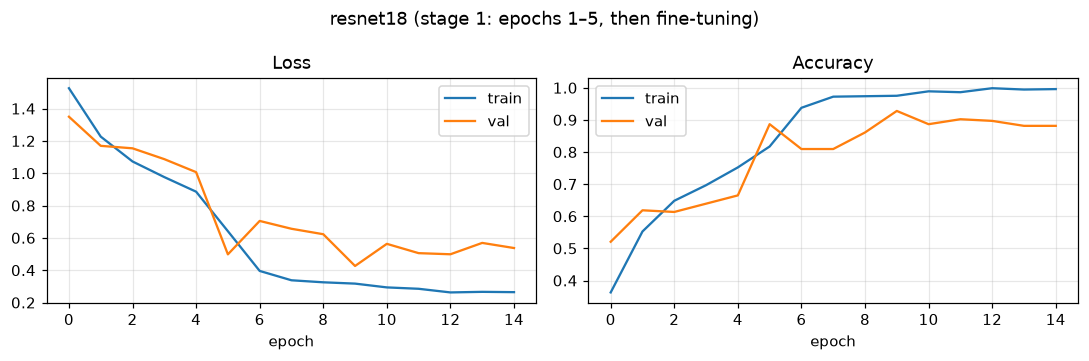

resnet18: test accuracy 0.969 | training time 2.2 min


In [11]:
ARCHS = ["resnet18"]          # optionally add "efficientnet_b0", "resnet50"
HEAD_EPOCHS, FT_EPOCHS = 5, 15

def build_model(name):
    if name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, len(CLASSES)); head = m.fc
    elif name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, len(CLASSES)); head = m.fc
    elif name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, len(CLASSES)); head = m.classifier
    else:
        raise ValueError(name)
    return m.to(DEVICE), head

def train_transfer(name):
    torch.manual_seed(SEED)
    model, head = build_model(name)
    print(f"\n=== {name}: {count_params(model):,} parameters ===")
    t0 = time.time()
    # stage 1: train the head only
    for p in model.parameters(): p.requires_grad = False
    for p in head.parameters(): p.requires_grad = True
    print("stage 1 — head only")
    hist = fit(model, torch.optim.Adam(head.parameters(), lr=1e-3), HEAD_EPOCHS, patience=HEAD_EPOCHS)
    stage1_epochs = len(hist["val_loss"])
    # stage 2: fine-tune everything
    for p in model.parameters(): p.requires_grad = True
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EPOCHS)
    print("stage 2 — fine-tuning")
    hist = fit(model, opt, FT_EPOCHS, sched, patience=5, history=hist)
    return model, hist, time.time() - t0, stage1_epochs

transfer = {}
for name in ARCHS:
    model, hist, t, s1 = train_transfer(name)
    pred, prob = predict(model, test_loader)
    transfer[name] = dict(model=model, hist=hist, time=t, pred=pred, prob=prob)
    plot_history(hist, f"{name} (stage 1: epochs 1–{s1}, then fine-tuning)", f"curves_{name}.png")
    torch.save(model.state_dict(), RESULTS / f"{name}_coins.pt")
    print(f"{name}: test accuracy {accuracy_score(test_df.label, pred):.3f} | training time {t / 60:.1f} min")

## 6. Evaluation & analysis
All metrics are computed on the **test set** (setup 1 — paper + daylight), which the models never saw during training or model selection.

In [12]:
y_true = test_df.label.to_numpy()
all_preds = {"HOG + SVM": svm_pred, "Simple CNN": cnn_pred}
for name, r in transfer.items():
    all_preds[f"{name} (transfer)"] = r["pred"]
train_times = {"HOG + SVM": svm_time, "Simple CNN": cnn_time,
               **{f"{n} (transfer)": r["time"] for n, r in transfer.items()}}
n_params = {"HOG + SVM": None, "Simple CNN": count_params(cnn),
            **{f"{n} (transfer)": count_params(r["model"]) for n, r in transfer.items()}}

rows = []
for name, pred in all_preds.items():
    p, r, f1, _ = precision_recall_fscore_support(y_true, pred, average="macro", zero_division=0)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_true, pred), "Precision (macro)": p,
                 "Recall (macro)": r, "F1 (macro)": f1, "Train time, s": train_times[name],
                 "Parameters": n_params[name]})
summary = pd.DataFrame(rows).set_index("Model")
summary.to_csv(RESULTS / "model_comparison.csv")
summary.style.format({"Accuracy": "{:.3f}", "Precision (macro)": "{:.3f}", "Recall (macro)": "{:.3f}",
                      "F1 (macro)": "{:.3f}", "Train time, s": "{:.0f}", "Parameters": "{:,.0f}"}, na_rep="—")

,Accuracy,Precision (macro),Recall (macro),F1 (macro),"Train time, s",Parameters
Model,,,,,,
HOG + SVM,0.218,0.181,0.222,0.159,0,—
Simple CNN,0.342,0.197,0.336,0.234,293,"390,661"
resnet18 (transfer),0.969,0.972,0.969,0.969,132,"11,179,077"


In [13]:
for name, pred in all_preds.items():
    print(f"===== {name} =====")
    print(classification_report(y_true, pred, labels=range(len(CLASSES)), target_names=SHORT, digits=3, zero_division=0))

===== HOG + SVM =====
              precision    recall  f1-score   support

           5      0.314     0.444     0.368        36
          10      0.214     0.075     0.111        40
          20      0.179     0.564     0.272        39
          50      0.000     0.000     0.000        39
         100      0.200     0.026     0.045        39

    accuracy                          0.218       193
   macro avg      0.181     0.222     0.159       193
weighted avg      0.179     0.218     0.156       193

===== Simple CNN =====
              precision    recall  f1-score   support

           5      0.000     0.000     0.000        36
          10      0.388     0.475     0.427        40
          20      0.000     0.000     0.000        39
          50      0.348     1.000     0.517        39
         100      0.250     0.205     0.225        39

    accuracy                          0.342       193
   macro avg      0.197     0.336     0.234       193
weighted avg      0.201     0.34

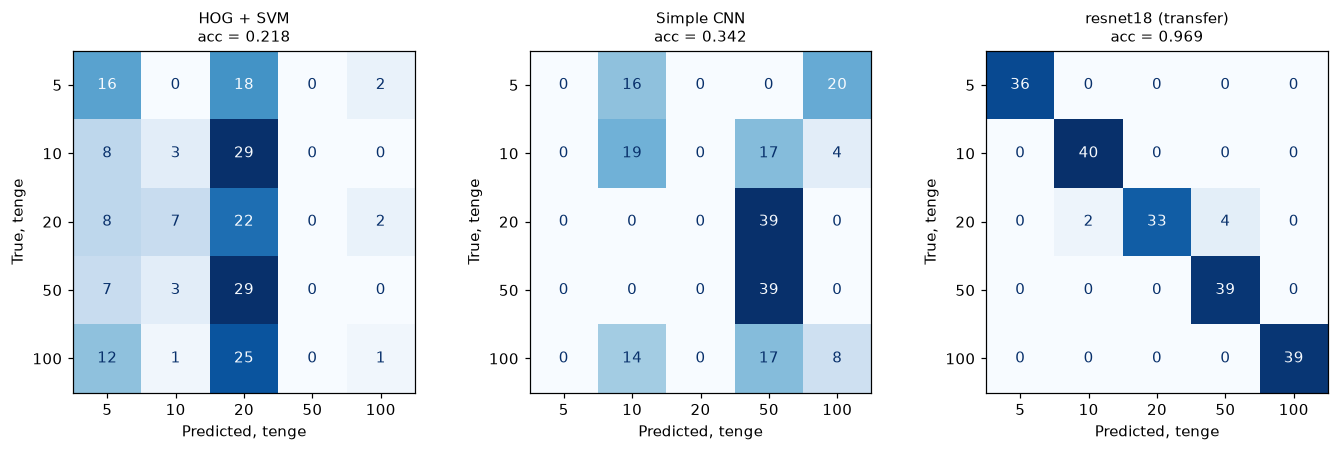

In [14]:
fig, axes = plt.subplots(1, len(all_preds), figsize=(4.2 * len(all_preds), 4))
axes = np.atleast_1d(axes)
for ax, (name, pred) in zip(axes, all_preds.items()):
    cm = confusion_matrix(y_true, pred, labels=range(len(CLASSES)))
    ConfusionMatrixDisplay(cm, display_labels=SHORT).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nacc = {accuracy_score(y_true, pred):.3f}", fontsize=10)
    ax.set_xlabel("Predicted, tenge"); ax.set_ylabel("True, tenge")
plt.tight_layout(); plt.savefig(RESULTS / "confusion_matrices.png"); plt.show()

### Accuracy by coin side
Is one side (obverse with the denomination / reverse) harder to recognise?

In [15]:
if "side" in test_df.columns:
    by_side = pd.DataFrame({name: pd.Series(pred == y_true).groupby(test_df["side"]).mean()
                            for name, pred in all_preds.items()})
    by_side.to_csv(RESULTS / "accuracy_by_side.csv")
    display(by_side.style.format("{:.3f}"))

,HOG + SVM,Simple CNN,resnet18 (transfer)
side,,,
obverse,0.224,0.357,0.969
reverse,0.211,0.326,0.968


### Misclassified examples (best model)

best model: resnet18 (transfer) — 6 errors out of 193


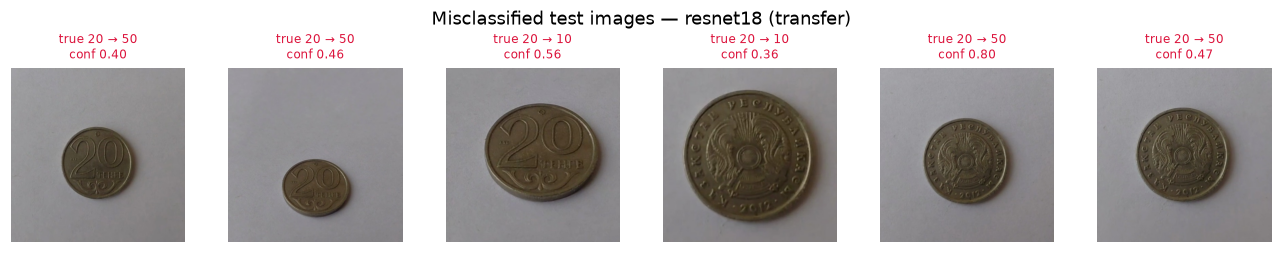

In [16]:
best_name = summary["F1 (macro)"].idxmax()
best_key = best_name.replace(" (transfer)", "")
if best_key in transfer:
    best_pred, best_prob = transfer[best_key]["pred"], transfer[best_key]["prob"]
else:
    best_pred, best_prob = cnn_pred, cnn_prob
wrong = np.where(best_pred != y_true)[0]
print(f"best model: {best_name} — {len(wrong)} errors out of {len(y_true)}")

if len(wrong):
    show = wrong[:12]
    cols = min(6, len(show)); rows_n = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 2, rows_n * 2.3), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, i in zip(axes.flat, show):
        ax.imshow(Image.open(DATA_DIR / test_df.path[i]))
        ax.set_title(f"true {SHORT[y_true[i]]} → {SHORT[best_pred[i]]}\n"
                     f"conf {best_prob[i].max():.2f}", fontsize=8, color="crimson")
    plt.suptitle(f"Misclassified test images — {best_name}"); plt.tight_layout()
    plt.savefig(RESULTS / "misclassified.png"); plt.show()

### Grad-CAM — where does the model look?
Grad-CAM highlights the image regions that most influenced the prediction. A good model should focus on the coin (digits, relief, rim), not on the background.

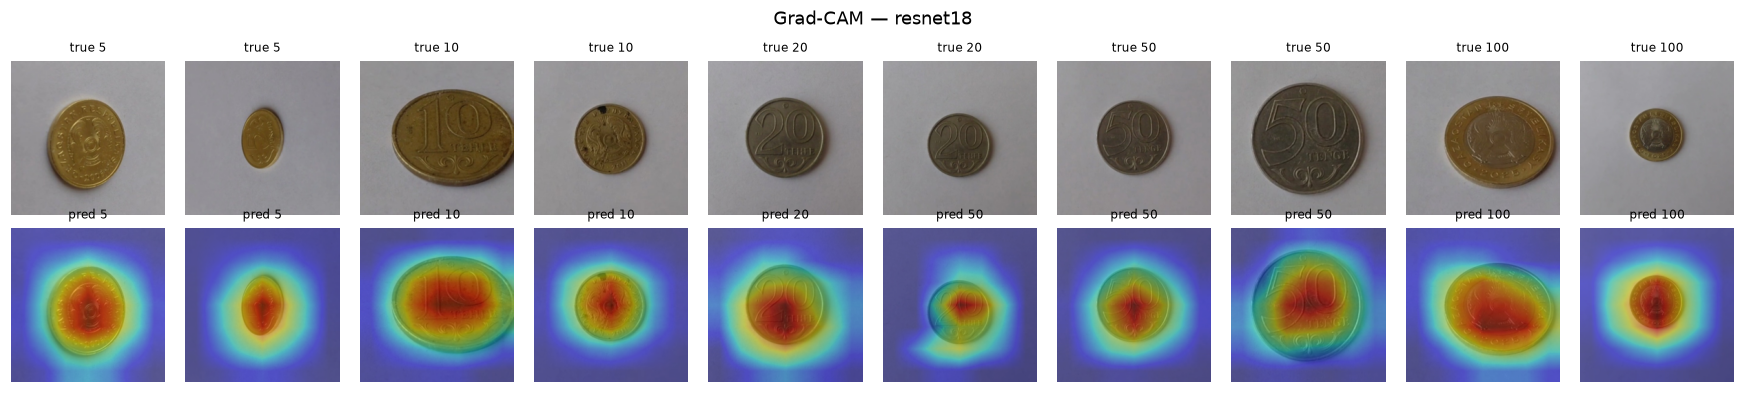

In [17]:
def grad_cam(model, x, target_layer):
    acts, grads = {}, {}
    def fwd_hook(module, inp, out):
        acts["a"] = out
        out.register_hook(lambda g: grads.__setitem__("g", g))   # gradient of the feature map
    h = target_layer.register_forward_hook(fwd_hook)
    model.eval()
    out = model(x.unsqueeze(0).to(DEVICE).requires_grad_(True))
    h.remove()
    idx = out.argmax(1).item()
    model.zero_grad()
    out[0, idx].backward()
    w = grads["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), idx

def target_layer_of(name, model):
    return model.layer4[-1] if name.startswith("resnet") else model.features[-1]

cam_name = ARCHS[0]
cam_model = transfer[cam_name]["model"]
layer = target_layer_of(cam_name, cam_model)
picks = test_df.groupby("label").sample(2, random_state=SEED).index.tolist()

fig, axes = plt.subplots(2, len(picks), figsize=(len(picks) * 1.6, 3.6))
for k, i in enumerate(picks):
    img = Image.open(DATA_DIR / test_df.path[i]).convert("RGB")
    x = eval_tf(img)
    cam, idx = grad_cam(cam_model, x, layer)
    axes[0][k].imshow(denorm(x)); axes[0][k].set_title(f"true {SHORT[test_df.label[i]]}", fontsize=8)
    axes[1][k].imshow(denorm(x)); axes[1][k].imshow(cam, cmap="jet", alpha=0.45)
    axes[1][k].set_title(f"pred {SHORT[idx]}", fontsize=8)
    for a in (axes[0][k], axes[1][k]): a.axis("off")
plt.suptitle(f"Grad-CAM — {cam_name}"); plt.tight_layout()
plt.savefig(RESULTS / "gradcam.png"); plt.show()

## 7. Conclusions
- **Best model:** ResNet18 with transfer learning — accuracy 0.969, macro F1 0.969 (6 errors out of 193 test images), trained in ~2 minutes.
- **Baselines:** HOG + SVM reached 0.218 accuracy (close to the 0.20 chance level), the simple CNN 0.342. Both learned features tied to the shooting conditions (background, lighting) and did not generalise to the unseen test setup. HOG is not rotation-invariant, and the colour histogram is dominated by the background. The CNN trained from scratch underfits (training accuracy ≈0.66 after 29 epochs, validation accuracy 0.3–0.5) and collapses to 2–3 classes on the test set.
- **Most confused classes:** all ResNet18 errors are 20-tenge coins, predicted as 50 (4) or 10 (2). These coins share the same colour, a similar obverse design and the same reverse emblem; in reality they differ mainly in physical size, which our crop-around-the-coin preprocessing removes. Most errors were made with low confidence (0.36–0.56).
- **Coin side:** accuracy is the same for obverse (0.969) and reverse (0.968), even though the reverse design is shared by several denominations. This suggests the model may partly recognise the specific coin specimens (wear, scratches, tint) rather than the denomination in general.
- **Grad-CAM:** the model focuses on the centre of the coin (digits, emblem), not on the background.
- **Limitations:** one physical coin per denomination; the test set uses a known background in a new lighting combination; images come from videos (frames are correlated); absolute coin size is lost after cropping.
- **Next steps:** more coins and issue years per denomination, unseen backgrounds and phones, keeping a size reference (e.g. a fixed camera distance or a reference object) to separate 10/20/50 tenge.